# Notebook 2: De Novo Molecular Generation & QSAR Virtual Screening (CDK2)

This notebook implements the **De Novo Generative Design** half of the *"Generative Design vs. The Catalogue"* pipeline for **CDK2 inhibitors**:

1. **Plug Into Existing QSAR Model:** Load `CDK2_clean.csv` and your saved QSAR surrogate model from Notebook 1.
2. **Prepare SELFIES Dataset:** Filter for potent CDK2 actives ($\text{pIC}_{50} \ge 7.0$), perform a Bemis-Murcko scaffold split (90% train / 10% validation), and encode canonical SMILES into **SELFIES**.
3. **Fine-Tune ChemGPT:** Fine-tune `ncfrey/ChemGPT-4.7M` via causal language modeling on potent CDK2 SELFIES strings.
4. **Generate 10,000 Molecules:** Sample 10,000 candidate sequences using nucleus sampling (`top_p`), decode back to RDKit canonical SMILES, and evaluate **Validity, Uniqueness, and Novelty**.
5. **Score, Filter & Pick Top 50:** Score all novel generated molecules with your QSAR model + medicinal-chemistry filters (**QED**, **Synthetic Accessibility (SA) Score**, Lipinski rules, scaffold diversity cap) and export the **Top 50** candidates.

In [1]:
# Install required packages in Google Colab
!pip install -q transformers datasets accelerate selfies rdkit joblib scikit-learn tqdm matplotlib seaborn

In [2]:
from google.colab import drive
drive.mount('/content/drive')

%cd "/content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject"

Mounted at /content/drive
/content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject


In [1]:
import os
import sys
import math
import json
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
    EarlyStoppingCallback,
)

import selfies as sf
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, QED, AllChem, DataStructs, RDConfig
from rdkit.Chem.Scaffolds import MurckoScaffold

# Suppress RDKit warnings during bulk decoding
RDLogger.DisableLog("rdApp.*")

# Import RDKit's Synthetic Accessibility (SA) scorer
sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score"))
import sascorer

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on device: {DEVICE}")

Running on device: cuda


## 1. Configuration & Google Drive Mounting

Update `BASE_DIR`, `DATA_PATH`, and `QSAR_MODEL_PATH` below to match the exact paths where Notebook 1 saved `CDK2_clean.csv` and your trained QSAR model.

In [2]:
# Mount Google Drive (set to False if uploading files directly to Colab session storage)
USE_GOOGLE_DRIVE = True

# --- Paths (adjust to match Notebook 1) ---
BASE_DIR = "/content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject" if USE_GOOGLE_DRIVE else "/content"
DATA_PATH = os.path.join(BASE_DIR, "data/processed", "CDK2_clean.csv")
QSAR_MODEL_PATH = os.path.join(BASE_DIR, "models", "CDK2_qsar_rf_baseline.joblib")
OUTPUT_DIR = os.path.join(BASE_DIR, "results_generative")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- Pipeline Hyperparameters ---
POTENCY_THRESHOLD = 7.0          # Fine-tune ChemGPT only on potent binders (pIC50 >= 7.0 -> IC50 <= 100 nM)
PRETRAINED_MODEL_NAME = "ncfrey/ChemGPT-4.7M"
N_GENERATE = 10_000              # Number of molecules to sample
TOP_K = 50                       # Final top candidates to select

## 2. Load Curated Dataset & Plug In Existing QSAR Model

The `predict_pic50()` wrapper below automatically handles:
* A plain scikit-learn estimator / `Pipeline` saved via `joblib.dump(model, ...)` (defaulting to 2048-bit radius-2 Morgan fingerprints, or matching `model.n_features_in_`).
* A dictionary artifact saved via `joblib.dump({"model": model, "radius": 2, "n_bits": 2048, "scaler": scaler}, ...)`.

If Notebook 1 concatenated extra RDKit physicochemical descriptors onto the fingerprint vector, update `featurize_smiles()` below so the feature columns match identically.

In [3]:
# Load curated CDK2 dataset
df_cdk2 = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df_cdk2):,} compounds from {DATA_PATH}")
display(df_cdk2.head(3))

def canonicalize(smiles):
    if not isinstance(smiles, str) or not smiles:
        return None
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(mol, canonical=True) if mol is not None else None

df_cdk2["canonical_smiles"] = df_cdk2["canonical_smiles"].apply(canonicalize)
df_cdk2 = df_cdk2.dropna(subset=["canonical_smiles"]).drop_duplicates("canonical_smiles").reset_index(drop=True)

# Full set of known CDK2 SMILES (used later to measure true novelty)
KNOWN_CDK2_SMILES = set(df_cdk2["canonical_smiles"])

# Load pre-trained QSAR model from Notebook 1
qsar_artifact = joblib.load(QSAR_MODEL_PATH)
print(f"Loaded QSAR artifact of type: {type(qsar_artifact)}")

Loaded 2,825 compounds from /content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject/data/processed/CDK2_clean.csv


,canonical_smiles,pIC50,n_measurements
0,Brc1cccc(-c2cc(NCc3ccncc3)n3nccc3n2)c1,5.744727,1
1,Brc1cccc(-c2cc(NCc3ccncc3)n3ncnc3n2)c1,4.585027,1
2,Brc1cnn2c(NCc3ccncc3)cc(-c3ccccc3)nc12,7.618286,2


Loaded QSAR artifact of type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [4]:
# ==============================================================================
# QSAR FEATURE & SCORING ADAPTER
# ==============================================================================

def compute_morgan_fp(smiles_list, radius=2, n_bits=2048):
    fps = np.zeros((len(smiles_list), n_bits), dtype=np.float32)
    for i, smi in enumerate(smiles_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            bv = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
            DataStructs.ConvertToNumpyArray(bv, fps[i])
    return fps

def predict_pic50(smiles_list, artifact=qsar_artifact):
    """
    Predicts pIC50 for a list of canonical SMILES using the loaded QSAR artifact.
    """
    if isinstance(artifact, dict):
        model = artifact["model"]
        if "featurizer" in artifact and callable(artifact["featurizer"]):
            X = artifact["featurizer"](smiles_list)
        else:
            radius = artifact.get("radius", 2)
            n_bits = artifact.get("n_bits", 2048)
            X = compute_morgan_fp(smiles_list, radius=radius, n_bits=n_bits)
            if "scaler" in artifact and artifact["scaler"] is not None:
                X = artifact["scaler"].transform(X)
        return np.asarray(model.predict(X), dtype=np.float64)
    else:
        n_features = int(getattr(artifact, "n_features_in_", 2048))
        X = compute_morgan_fp(smiles_list, radius=2, n_bits=n_features)
        return np.asarray(artifact.predict(X), dtype=np.float64)

# Sanity check QSAR model on 5 compounds from CDK2_clean.csv
sample_check = df_cdk2.sample(5, random_state=SEED)
preds = predict_pic50(sample_check["canonical_smiles"].tolist())
for smi, true_val, pred_val in zip(sample_check["canonical_smiles"], sample_check["pIC50"], preds):
    print(f"True pIC50: {true_val:.2f} | QSAR Pred: {pred_val:.2f} | SMILES: {smi[:48]}...")

True pIC50: 4.64 | QSAR Pred: 5.35 | SMILES: COc1cc(C2=C(c3cn(COC(C)(C)C)c4ccccc34)CNC2=O)cc(...
True pIC50: 5.00 | QSAR Pred: 5.37 | SMILES: Nc1nccc(-c2c[nH]c3ncccc23)n1...
True pIC50: 8.05 | QSAR Pred: 7.99 | SMILES: C[C@@H](O)[C@@H](C)Nc1nc(Nc2ccc([S@](=N)(=O)C3CC...
True pIC50: 6.52 | QSAR Pred: 5.57 | SMILES: O=C(O)c1cc(S(F)(F)(F)(F)F)ccc1NCCc1c[nH]c2ccccc1...
True pIC50: 5.00 | QSAR Pred: 5.41 | SMILES: COc1cc(F)ccc1-c1cc(Nc2ccc(NC(=O)CCCCCCC(=O)Nc3cc...


## 3. Filter Potent Actives, Scaffold Split & Encode to SELFIES

* **Potency Filtering:** Only compounds with $\text{pIC}_{50} \ge 7.0$ are used to fine-tune ChemGPT so it generates potent CDK2 inhibitors rather than weak/inactive compounds.
* **Scaffold Split (90% Train / 10% Validation):** Grouping by Bemis-Murcko scaffolds prevents analog leakage into the validation split.
* **SELFIES Encoding & Vocabulary Verification:** `ncfrey/ChemGPT-4.7M` is trained on SELFIES strings. We verify that every SELFIES token present in our CDK2 subset exists in the tokenizer vocabulary (and add/resize embeddings for any rare token if needed).

In [5]:
# 1. Filter for potent active compounds
df_actives = df_cdk2[df_cdk2["pIC50"] >= POTENCY_THRESHOLD].copy().reset_index(drop=True)
print(f"Potent actives (pIC50 >= {POTENCY_THRESHOLD}): {len(df_actives):,} / {len(df_cdk2):,} compounds")

# 2. Convert SMILES -> SELFIES
def smiles_to_selfies_safe(smi):
    try:
        return sf.encoder(smi)
    except Exception:
        return None

df_actives["selfies"] = df_actives["canonical_smiles"].apply(smiles_to_selfies_safe)
df_actives = df_actives.dropna(subset=["selfies"]).reset_index(drop=True)
print(f"Successfully encoded to SELFIES: {len(df_actives):,}")

# 3. Bemis-Murcko Scaffold Split (90% Train / 10% Val)
def get_scaffold(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return ""
    return MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)

df_actives["scaffold"] = df_actives["canonical_smiles"].apply(get_scaffold)
scaffold_groups = df_actives.groupby("scaffold").indices
sorted_scaffolds = sorted(scaffold_groups.items(), key=lambda x: len(x[1]), reverse=True)

train_idx, val_idx = [], []
val_target_size = int(0.10 * len(df_actives))
for scaf, idxs in sorted_scaffolds:
    if len(val_idx) < val_target_size and len(idxs) <= max(5, val_target_size // 3):
        val_idx.extend(idxs)
    else:
        train_idx.extend(idxs)

train_selfies = df_actives.iloc[train_idx]["selfies"].tolist()
val_selfies = df_actives.iloc[val_idx]["selfies"].tolist()
print(f"Train SELFIES: {len(train_selfies):,} | Validation SELFIES: {len(val_selfies):,}")

Potent actives (pIC50 >= 7.0): 864 / 2,825 compounds
Successfully encoded to SELFIES: 864
Train SELFIES: 767 | Validation SELFIES: 97


In [6]:
# 4. Load ChemGPT Tokenizer & Model + Register Native Special Tokens
tokenizer = AutoTokenizer.from_pretrained(PRETRAINED_MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(PRETRAINED_MODEL_NAME)

# Map ChemGPT's existing [CLS], [SEP], [PAD] tokens into Hugging Face's special token slots
vocab = tokenizer.get_vocab()
tokenizer.add_special_tokens({
    "bos_token": "[CLS]",
    "eos_token": "[SEP]",
    "pad_token": "[PAD]",
    "unk_token": "[UNK]",
    "mask_token": "[MASK]",
})

model.config.bos_token_id = vocab["[CLS]"]
model.config.eos_token_id = vocab["[SEP]"]
model.config.pad_token_id = vocab["[PAD]"]

# Check whether any CDK2 SELFIES token is missing from the ChemGPT vocabulary
all_cdk2_alphabet = sf.get_alphabet_from_selfies(df_actives["selfies"].tolist())
existing_vocab = set(tokenizer.get_vocab().keys())
missing_tokens = sorted([tok for tok in all_cdk2_alphabet if tok not in existing_vocab])

if missing_tokens:
    print(f"Adding {len(missing_tokens)} unseen SELFIES tokens to tokenizer: {missing_tokens}")
    tokenizer.add_tokens(missing_tokens)
    model.resize_token_embeddings(len(tokenizer))
else:
    print("All CDK2 SELFIES tokens are already covered by the ChemGPT vocabulary.")

# Sanity check: verify [CLS] and [SEP] wrap encoded sequences automatically
sample_ids = tokenizer.encode(train_selfies[0])
print("Start/End tokens:", tokenizer.decode([sample_ids[0], sample_ids[-1]]))

tokenized_lengths = [len(tokenizer.encode(s)) for s in df_actives["selfies"]]
MAX_LEN = min(256, max(tokenized_lengths) + 16)
print(f"Max token length in dataset: {max(tokenized_lengths)} -> using MAX_LEN = {MAX_LEN}")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 683), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 683), got 50256. This may result in unexpected behavior.


Loading weights:   0%|          | 0/316 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: ncfrey/ChemGPT-4.7M
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...22}.attn.attention.bias        | UNEXPECTED |  | 
transformer.h.{0...23}.attn.attention.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Adding 28 unseen SELFIES tokens to tokenizer: ['[#Branch1]', '[#Branch2]', '[-/Ring2]', '[/C]', '[/N]', '[/O]', '[/S]', '[2H]', '[=Branch1]', '[=Branch2]', '[=N+1]', '[=Ring1]', '[=Ring2]', '[Branch1]', '[Branch2]', '[C@@H1]', '[C@@]', '[C@H1]', '[C@]', '[N+1]', '[NH1]', '[O-1]', '[S+1]', '[S@]', '[Si]', '[\\C]', '[\\N]', '[\\O]']
Start/End tokens: [CLS] [SEP]
Max token length in dataset: 135 -> using MAX_LEN = 151


## 4. Fine-Tune `ncfrey/ChemGPT-4.7M` on Potent CDK2 Inhibitors

We fine-tune `ChemGPT-4.7M` with causal language modeling (`mlm=False`), cosine learning-rate decay, `fp16` mixed precision on T4 GPU, and `EarlyStoppingCallback` monitoring `eval_loss` so the model adapts to CDK2 hinge-binding motifs without memorizing the training set.

Fine-Tuning is done on the whole model, with no frozen weights.

In [7]:
class SelfiesDataset(Dataset):
    def __init__(self, selfies_list, tokenizer, max_length):
        self.encodings = tokenizer(
            selfies_list,
            truncation=True,
            max_length=max_length,
            padding=False,
        )

    def __len__(self):
        return len(self.encodings["input_ids"])

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
        }


train_dataset = SelfiesDataset(train_selfies, tokenizer, MAX_LEN)
val_dataset = SelfiesDataset(val_selfies, tokenizer, MAX_LEN)
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

chemgpt_ckpt_dir = os.path.join(OUTPUT_DIR, "chemgpt_cdk2_finetuned")

training_args = TrainingArguments(
    output_dir=chemgpt_ckpt_dir,
    num_train_epochs=15,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    learning_rate=8e-5,
    weight_decay=0.01,
    warmup_steps=15,
    lr_scheduler_type="cosine",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

train_result = trainer.train()
trainer.save_model(chemgpt_ckpt_dir)
tokenizer.save_pretrained(chemgpt_ckpt_dir)
print("Fine-tuning complete. Best checkpoint saved to:", chemgpt_ckpt_dir)

Epoch,Training Loss,Validation Loss
1,4.004183,2.872549
2,2.584445,2.472194
3,2.188974,2.177690
4,1.894816,1.967472
5,1.637851,1.804763
6,1.428143,1.662806
7,1.262628,1.587976
8,1.134088,1.555480
9,1.035027,1.509886
10,0.959815,1.533292


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning complete. Best checkpoint saved to: /content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject/results_generative/chemgpt_cdk2_finetuned


## 5. De Novo Sampling: Generate 10,000 Candidate Molecules

We generate `10,000` molecules in batches on the GPU using nucleus sampling (`top_p=0.92`, `temperature=0.95`), decode each SELFIES string back to RDKit canonical SMILES, and compute standard generative benchmarks:
* **Validity:** Fraction of generated strings that decode into valid RDKit molecules ($\ge 6$ heavy atoms).
* **Uniqueness:** Fraction of valid molecules that are structurally distinct.
* **Novelty:** Fraction of unique valid molecules that do **not** appear anywhere in `CDK2_clean.csv`.

In [8]:
model.to(DEVICE)
model.eval()

def generate_selfies_batch(model, tokenizer, n_samples, batch_size=250, max_new_tokens=140, temperature=0.80, top_p=0.88):
    generated_strings = []
    bos_id = tokenizer.bos_token_id  # Native [CLS] token
    eos_id = tokenizer.eos_token_id  # Native [SEP] token
    pad_id = tokenizer.pad_token_id  # Native [PAD] token

    n_batches = math.ceil(n_samples / batch_size)
    with torch.no_grad():
        for _ in tqdm(range(n_batches), desc="Generating 10,000 SELFIES"):
            curr_bs = min(batch_size, n_samples - len(generated_strings))
            input_ids = torch.full((curr_bs, 1), bos_id, dtype=torch.long, device=DEVICE)
            attention_mask = torch.ones_like(input_ids)

            outputs = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_new_tokens=max_new_tokens,
                do_sample=True,
                temperature=temperature,
                top_p=top_p,
                pad_token_id=pad_id,
                eos_token_id=eos_id,
            )

            decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
            cleaned = [s.replace(" ", "").strip() for s in decoded]
            generated_strings.extend(cleaned)

    return generated_strings[:n_samples]


raw_selfies = generate_selfies_batch(
    model=model,
    tokenizer=tokenizer,
    n_samples=N_GENERATE,
    batch_size=250,
    max_new_tokens=MAX_LEN,
    temperature=0.80,
    top_p=0.88,
)

# Decode SELFIES -> Canonical SMILES
valid_smiles = []
for s in tqdm(raw_selfies, desc="Decoding SELFIES to SMILES"):
    if not s:
        continue
    try:
        smi = sf.decoder(s)
        mol = Chem.MolFromSmiles(smi)
        if mol is not None and mol.GetNumHeavyAtoms() >= 6:
            can_smi = Chem.MolToSmiles(mol, canonical=True)
            valid_smiles.append(can_smi)
    except Exception:
        continue

unique_smiles = list(dict.fromkeys(valid_smiles))
novel_smiles = [smi for smi in unique_smiles if smi not in KNOWN_CDK2_SMILES]

validity_pct = 100.0 * len(valid_smiles) / N_GENERATE
uniqueness_pct = 100.0 * len(unique_smiles) / max(1, len(valid_smiles))
novelty_pct = 100.0 * len(novel_smiles) / max(1, len(unique_smiles))

print(f"Total Sampled : {N_GENERATE:,}")
print(f"Valid         : {len(valid_smiles):,} ({validity_pct:.2f}%)")
print(f"Unique        : {len(unique_smiles):,} ({uniqueness_pct:.2f}%)")
print(f"Novel         : {len(novel_smiles):,} ({novelty_pct:.2f}%)")
print("Sample decoded SMILES:", valid_smiles[:5])

Generating 10,000 SELFIES:   0%|          | 0/40 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=151) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=151) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=151) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=151) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Decoding SELFIES to SMILES:   0%|          | 0/10000 [00:00<?, ?it/s]

Total Sampled : 10,000
Valid         : 9,464 (94.64%)
Unique        : 8,606 (90.93%)
Novel         : 8,606 (100.00%)
Sample decoded SMILES: ['CN1CC2N=NC(CC3C=CN=CCNCCNC3)=CCNCCOC2C1', 'NC=C1CCC(C=CN=CC(=CC=CS(N)(=O)=O)ON)C=CC=CCC1Br', 'C=C1N=NC([SH](O)[CH]C=O)=CC=CNC(=N)N=CC1=CNCCCNC', 'O=CC=CC=CN[C@@H]1CN=CC[C@@H]2C=CN=CC21', 'CC1=CC=C(ON)C=NC=C2C(=C(C)CN1)C=CN=C(C)N2C=N']


## 6. Score Novel Molecules with QSAR & Pick the Top 50 Candidates

To prevent **QSAR exploitation** (where a generative model produces overly lipophilic, giant, or synthetically intractable molecules that trick a fingerprint model), we compute:
1. **Predicted $\text{pIC}_{50}$** using your QSAR model from Notebook 1.
2. **QED** (Quantitative Estimate of Drug-likeness, $0 \to 1$, higher is better).
3. **SA Score** (Synthetic Accessibility, $1 \to 10$, lower is easier to synthesize; $\text{SA} \le 4.5$ is standard).
4. **Medicinal-Chemistry & Ring-Size Filters** ($\text{MW} \in [180, 550]$, $\text{LogP} \in [-1.0, 5.5]$, $\text{HBD} \le 5$, $\text{HBA} \le 10$, $\text{TPSA} \le 140$, max ring size $\le 7$) plus a **scaffold diversity cap** (at most 3 molecules per Murcko scaffold in the Top 50).

In [9]:
# Compute physicochemical properties & SA score for all novel generated molecules
records = []
for smi in tqdm(novel_smiles, desc="Computing physicochemical descriptors"):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        continue
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Descriptors.NumHDonors(mol)
    hba = Descriptors.NumHAcceptors(mol)
    tpsa = Descriptors.TPSA(mol)
    rotb = Descriptors.NumRotatableBonds(mol)
    qed_val = QED.qed(mol)
    sa_val = sascorer.calculateScore(mol)
    scaf = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=False)
    ring_info = mol.GetRingInfo()
    max_ring = max((len(r) for r in ring_info.AtomRings()), default=0)

    records.append({
        "canonical_smiles": smi,
        "scaffold": scaf,
        "MolWt": mw,
        "LogP": logp,
        "HBD": hbd,
        "HBA": hba,
        "TPSA": tpsa,
        "RotBonds": rotb,
        "MaxRingSize": max_ring,
        "QED": qed_val,
        "SA_Score": sa_val,
    })

df_gen = pd.DataFrame(records)

# Score all novel molecules with the saved QSAR model
df_gen["pred_pIC50"] = predict_pic50(df_gen["canonical_smiles"].tolist())

# Compute maximum Morgan Tanimoto similarity to known potent CDK2 actives
active_fps = [
    AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, nBits=2048)
    for s in df_actives["canonical_smiles"]
]

max_sims = []
for smi in tqdm(df_gen["canonical_smiles"], desc="Computing nearest-neighbor Tanimoto similarity"):
    fp = AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(smi), 2, nBits=2048)
    sims = DataStructs.BulkTanimotoSimilarity(fp, active_fps)
    max_sims.append(max(sims) if sims else 0.0)
df_gen["max_sim_to_actives"] = max_sims

# Save full scored library (use this for distribution comparison against the catalogue)
full_gen_path = os.path.join(OUTPUT_DIR, "chemgpt_10k_all_novel_scored.csv")
df_gen.to_csv(full_gen_path, index=False)
print(f"Saved all {len(df_gen):,} scored novel molecules to {full_gen_path}")

Computing physicochemical descriptors:   0%|          | 0/8606 [00:00<?, ?it/s]

Computing nearest-neighbor Tanimoto similarity:   0%|          | 0/8606 [00:00<?, ?it/s]

Saved all 8,606 scored novel molecules to /content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject/results_generative/chemgpt_10k_all_novel_scored.csv


In [10]:
# Apply drug-likeness & synthetic accessibility quality filters
quality_mask = (
    (df_gen["MolWt"].between(180, 550)) &
    (df_gen["LogP"].between(-1.0, 5.5)) &
    (df_gen["HBD"] <= 5) &
    (df_gen["HBA"] <= 10) &
    (df_gen["TPSA"] <= 140) &
    (df_gen["MaxRingSize"] <= 7) &
    (df_gen["QED"] >= 0.40) &
    (df_gen["SA_Score"] <= 4.5)
)

df_filtered = df_gen[quality_mask].copy()
print(f"Passed med-chem & SA filters: {len(df_filtered):,} / {len(df_gen):,} novel molecules")

# Rank by predicted pIC50 with a scaffold diversity cap (max 3 per Murcko scaffold)
df_filtered = df_filtered.sort_values(by="pred_pIC50", ascending=False).reset_index(drop=True)
df_filtered["scaffold_rank"] = df_filtered.groupby("scaffold").cumcount()
df_diverse_pool = df_filtered[df_filtered["scaffold_rank"] < 3].copy()

# Pick the Top 50 candidates
df_top50 = df_diverse_pool.head(TOP_K).drop(columns=["scaffold_rank"]).reset_index(drop=True)
df_top50.index = df_top50.index + 1
df_top50.index.name = "Rank"

top50_path = os.path.join(OUTPUT_DIR, "chemgpt_top50_candidates.csv")
df_top50.to_csv(top50_path)
print(f"Saved Top {len(df_top50)} de novo candidates to {top50_path}")

display(df_top50[["canonical_smiles", "pred_pIC50", "QED", "SA_Score", "MolWt", "LogP", "max_sim_to_actives"]].head(15))

Passed med-chem & SA filters: 104 / 8,606 novel molecules
Saved Top 50 de novo candidates to /content/drive/MyDrive/Studium/Master/Semester abroad/Bioinformatics/BioInfProject/results_generative/chemgpt_top50_candidates.csv


,canonical_smiles,pred_pIC50,QED,SA_Score,MolWt,LogP,max_sim_to_actives
Rank,,,,,,,
1,Cc1ncc(-c2ccnc(NC3=CC(=C[SH](N)O)C=C3)n2)n1C(C)C,7.956160,0.611648,4.237240,358.471,3.32682,0.538462
2,CC=NC=C1C=CN=C(Nc2ccc(S(=O)(=O)c3ccccc3F)cc2)N=C1,6.934369,0.793153,3.391984,396.447,3.99910,0.256098
3,C=Cc1cnc(Nc2ccc(C(O)NC3CCN(C)C3)cc2)nc1N=CC,6.467149,0.516034,3.976014,366.469,2.87000,0.337209
4,CC(C)N1CC=NC=C1C1=NC(NC=C2C=CC(C(N)CCNC3CCCCC3...,6.383872,0.561924,4.367964,421.593,3.00010,0.163043
5,CC=CN=CNc1nccc(NC2=CC=CC(=O)NC2)n1,6.256010,0.561817,3.977173,284.323,1.43220,0.250000
6,CNCC=NC=C(N)c1nccc(C=CN=Cc2ccn[nH]2)n1,6.123454,0.654952,4.333545,310.365,0.83680,0.175000
7,CNCCN=CCC=C(N)c1nccc(C=CN=Cc2ccn[nH]2)n1,6.096093,0.470003,4.232635,338.419,1.26940,0.179775
8,CC1=CN=CC[C@H](NCN2C=CC=CC2)C1,6.059321,0.783259,4.488682,217.316,2.05600,0.154762
9,CCC1N=CC=CCN1CCNC,6.052065,0.697086,4.119874,181.283,0.88450,0.147727


## 7. Diagnostics & Visualization (Ready for Catalogue Comparison)

Inspect the predicted potency, QED, synthetic accessibility, and nearest-neighbor Tanimoto similarity distributions of your generated library vs. the Top 50 hits. You can load `chemgpt_10k_all_novel_scored.csv` and `chemgpt_top50_candidates.csv` directly alongside your screened catalogue CSV for head-to-head comparison plots and 3D docking.

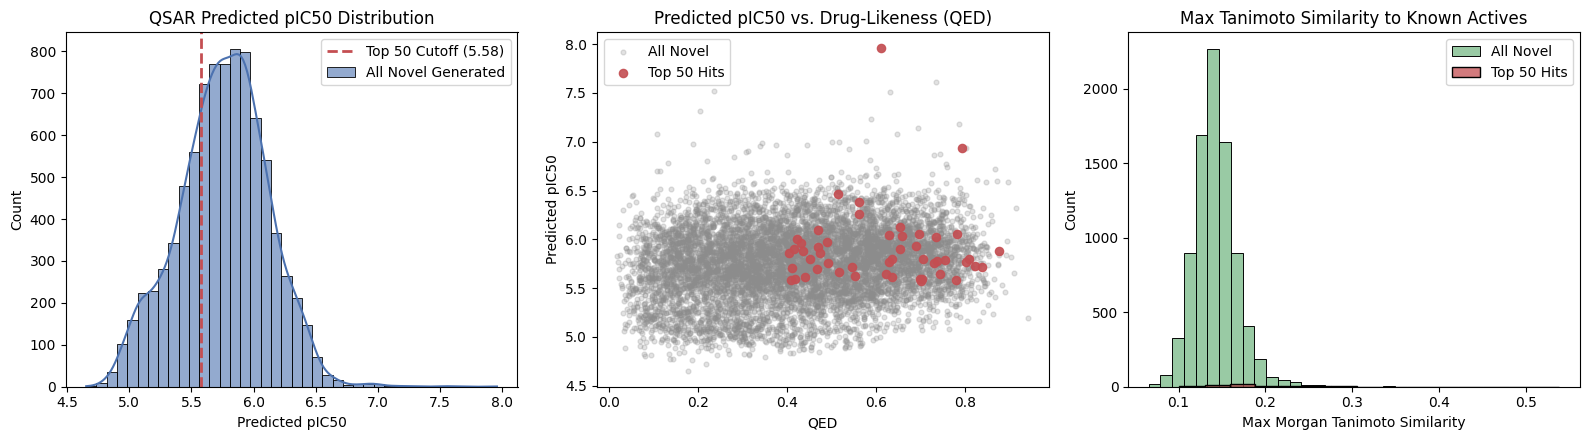

=== Summary Metrics for Report ===
Mean Predicted pIC50 (All Novel) : 5.76 +/- 0.36
Mean Predicted pIC50 (Top 50)    : 5.90 +/- 0.39
Mean QED (Top 50)                : 0.610
Mean SA Score (Top 50)           : 4.10
Unique Murcko Scaffolds in Top 50: 46 / 50
Completely Novel Scaffolds Top 50: 45


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Panel A: Predicted pIC50 distribution
sns.histplot(df_gen["pred_pIC50"], bins=40, kde=True, color="#4C72B0", alpha=0.6, label="All Novel Generated", ax=axes[0])
axes[0].axvline(df_top50["pred_pIC50"].min(), color="#C44E52", linestyle="--", linewidth=2,
                label=f"Top 50 Cutoff ({df_top50['pred_pIC50'].min():.2f})")
axes[0].set_title("QSAR Predicted pIC50 Distribution")
axes[0].set_xlabel("Predicted pIC50")
axes[0].legend()

# Panel B: Potency vs Drug-Likeness (QED)
axes[1].scatter(df_gen["QED"], df_gen["pred_pIC50"], alpha=0.25, s=12, color="#8C8C8C", label="All Novel")
axes[1].scatter(df_top50["QED"], df_top50["pred_pIC50"], alpha=0.9, s=35, color="#C44E52", label="Top 50 Hits")
axes[1].set_title("Predicted pIC50 vs. Drug-Likeness (QED)")
axes[1].set_xlabel("QED")
axes[1].set_ylabel("Predicted pIC50")
axes[1].legend()

# Panel C: Nearest-Neighbor Tanimoto Similarity to Known CDK2 Actives
sns.histplot(df_gen["max_sim_to_actives"], bins=35, color="#55A868", alpha=0.6, label="All Novel", ax=axes[2])
sns.histplot(df_top50["max_sim_to_actives"], bins=15, color="#C44E52", alpha=0.75, label="Top 50 Hits", ax=axes[2])
axes[2].set_title("Max Tanimoto Similarity to Known Actives")
axes[2].set_xlabel("Max Morgan Tanimoto Similarity")
axes[2].legend()

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "chemgpt_generation_summary.png")
plt.savefig(plot_path, dpi=300)
plt.show()

# Summary metrics for report
known_scaffolds = set(df_cdk2["canonical_smiles"].apply(get_scaffold))
novel_top50_scaffolds = set(df_top50["scaffold"]) - known_scaffolds
print("=== Summary Metrics for Report ===")
print(f"Mean Predicted pIC50 (All Novel) : {df_gen['pred_pIC50'].mean():.2f} +/- {df_gen['pred_pIC50'].std():.2f}")
print(f"Mean Predicted pIC50 (Top 50)    : {df_top50['pred_pIC50'].mean():.2f} +/- {df_top50['pred_pIC50'].std():.2f}")
print(f"Mean QED (Top 50)                : {df_top50['QED'].mean():.3f}")
print(f"Mean SA Score (Top 50)           : {df_top50['SA_Score'].mean():.2f}")
print(f"Unique Murcko Scaffolds in Top 50: {df_top50['scaffold'].nunique()} / {len(df_top50)}")
print(f"Completely Novel Scaffolds Top 50: {len(novel_top50_scaffolds)}")